# Categorical feature selection

The string counterpart of notebooks 02–05. Separates identifiers from real categoricals,
scores every candidate against asking rent, and resolves nested geography into one level.

**Project step:** §4.2 step 1.0, string variables.

**Inputs:** `data/master_listing.parquet`, `data/master_columns.csv`.

**Outputs:** `outputs/07_phase_01_feature_funnel_categorical{suffix}.csv`,
`outputs/07_phase_01_feature_selection_categorical{suffix}.csv`,
`outputs/07_phase_01_cramers_v_pairs{suffix}.csv`,
`outputs/07_phase_01_categorical_final_features{suffix}.csv`,
`outputs/07_phase_01_categorical_importance{suffix}.png`.

**Run after:** 02_feature_funnel. Independent of 03–05, which cover numeric variables.

**Runtime:** ~1 min at the default sample.

## Two rules this notebook enforces

**Cardinality is judged per entity, not per row.** `market_building__street_address` holds
2,999 distinct values across 3,000 buildings — a building identifier. Measured across
listings it is only 2.5% distinct, because each building repeats over roughly 320 of them,
so a row-based threshold lets it through as a feature.

**Decisions follow held-out importance, not in-sample fit.** `eta_sq` ranks those building
identifiers top (`street_address` 0.73) while their permutation importance on unseen
buildings is nil (0.14; `building_name` is negative). Target-encoding a building label
teaches you nothing about a building you have not seen. Selecting on `eta_sq` keeps the
identifiers and discards `property_class`, `zip_code` and `submarket` as redundant with them.


In [1]:
# ---- Data ----
INPUT = "data/master_listing.parquet"   # relative to the repo root
OUTPUT_DIR = "outputs"                  # every CSV / XLSX / PNG goes here

# ---- Filters (None = no filter) ----
CITY = None             # "chicago", "dfw", "dc", or a list of them       -> column `market`
NEIGHBORHOOD = None     # submarket or list -> `market_building__submarket`
START_DATE = None       # "YYYY-MM-DD": keep listings with DATE_COLUMN >= START_DATE
END_DATE = None         # "YYYY-MM-DD": keep listings with DATE_COLUMN <= END_DATE
DATE_COLUMN = "market_unit__enter_market"

# ---- Target ----
TARGET = "market_price_observation__first_asking_rent"
ANSWER_KEY = "truth_floorplan_market_rent__true_market_rent_at_enter"

# ---- Selection ----
SAMPLE_N = 120_000      # rows scored; None = all rows with a target
MI_N = 50_000           # rows used for mutual information
SHUFFLES = 3            # label shuffles behind the eta_sq null baseline
ID_CARDINALITY = 0.20   # distinct values per entity above which a column is an identifier
MIN_COMPLETENESS = 50   # %
MIN_GAIN = 0.0          # minimum held-out perm_dMAE, in dollars of MAE
REDUNDANT_V = 0.9       # Cramer's V above which two columns are compared
INCLUDE_TRUTH = False   # also score latent/label strings, for validation only

In [2]:
from pathlib import Path
import sys

import pandas as pd

BLUE, GREEN, YELLOW, RED, BOLD, RESET = "\033[94m", "\033[92m", "\033[93m", "\033[91m", "\033[1m", "\033[0m"


def step(msg):
    print(f"\n{BOLD}{BLUE}▶ {msg}{RESET}")


def done(msg):
    print(f"{GREEN}  ✓ {msg}{RESET}")


def note(msg):
    print(f"{YELLOW}  • {msg}{RESET}")


ROOT = Path.cwd()
while not (ROOT / "data" / "master_listing.parquet").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
MASTER = ROOT / INPUT
CATALOG = ROOT / "data" / "master_columns.csv"
OUTPUTS = ROOT / OUTPUT_DIR
OUTPUTS.mkdir(parents=True, exist_ok=True)
NN = 7
FILTER_COLUMNS = ["market", "market_building__submarket", DATE_COLUMN]

# The scoring functions live in preprocessing/analyze_categorical.py so the same
# code backs this notebook and the command line.
sys.path.insert(0, str(ROOT / "preprocessing"))
import analyze_categorical as ac


def _as_list(value):
    """Normalize one filter value or a list of values."""
    if value is None:
        return None
    return [value] if isinstance(value, str) else list(value)


def suffix():
    """Build the shared output suffix from the active filters."""
    parts = []
    if CITY is not None:
        parts.append("+".join(map(str, _as_list(CITY))))
    if NEIGHBORHOOD is not None:
        parts.append("+".join(map(str, _as_list(NEIGHBORHOOD))))
    if START_DATE is not None or END_DATE is not None:
        parts.append(f"{START_DATE or 'start'}_to_{END_DATE or 'end'}")
    return "" if not parts else "__" + "__".join(parts)


def out(name, ext="csv"):
    """Build an output path with this notebook's number and active filters."""
    return OUTPUTS / f"{NN:02d}_phase_01_{name}{suffix()}.{ext}"


def load(columns):
    """Read requested master columns and apply the configured listing filters."""
    requested = list(dict.fromkeys(columns))
    read_columns = list(dict.fromkeys(requested + FILTER_COLUMNS))
    frame = pd.read_parquet(MASTER, columns=read_columns)
    valid_values = {
        column: sorted(frame[column].dropna().astype(str).unique())
        for column in ("market", "market_building__submarket")
    }
    for column, value, label in (
        ("market", CITY, "city"),
        ("market_building__submarket", NEIGHBORHOOD, "neighborhood"),
    ):
        if value is not None:
            wanted = list(map(str, _as_list(value)))
            valid = valid_values[column]
            unknown = sorted(set(wanted) - set(valid))
            if unknown:
                raise ValueError(f"Unknown {label}(s) {unknown}. Valid values: {valid}")
            before = len(frame)
            frame = frame[frame[column].astype(str).isin(wanted)]
            note(f"{label}: {before:,} → {len(frame):,} rows")
    if START_DATE is not None:
        before = len(frame)
        frame = frame[frame[DATE_COLUMN] >= pd.Timestamp(START_DATE)]
        note(f"start date: {before:,} → {len(frame):,} rows")
    if END_DATE is not None:
        before = len(frame)
        frame = frame[frame[DATE_COLUMN] <= pd.Timestamp(END_DATE)]
        note(f"end date: {before:,} → {len(frame):,} rows")
    return frame[requested]


## Funnel

Every string column with its grain, its cardinality against the entities it varies over,
and why it is in or out.

In [3]:
ac.ID_CARDINALITY = ID_CARDINALITY

step("Reading the string columns from the master table")
catalog = pd.read_csv(CATALOG)
strings = catalog[catalog["type_group"] == "string"]
frame = load(strings["column"].tolist() + ["property_id", TARGET])
frame = frame[frame[TARGET].notna()].reset_index(drop=True)
if SAMPLE_N and SAMPLE_N < len(frame):
    frame = frame.sample(SAMPLE_N, random_state=ac.SEED).reset_index(drop=True)
done(f"{len(frame):,} rows with a target x {len(strings)} string columns")

step("Classifying each column: identifier, post-listing, truth, or candidate")
funnel = ac.classify(strings, frame, len(frame), INCLUDE_TRUTH)
funnel.to_csv(out("feature_funnel_categorical"), index=False)
for status, n in funnel["x_status"].value_counts().items():
    note(f"{status:12s}{n:>3} columns")
candidates = funnel.loc[funnel["x_status"] == "candidate", "variable"].tolist()
done(f"{len(candidates)} candidates")

ids = funnel[funnel["reason"].str.startswith("identifier")]
if len(ids):
    print(f"\n{BOLD}Excluded as identifiers{RESET}")
    print(ids[["variable", "grain", "n_levels", "n_entities", "cardinality_ratio"]].to_string(index=False))
funnel


▶ Reading the string columns from the master table


  ✓ 120,000 rows with a target x 36 string columns

▶ Classifying each column: identifier, post-listing, truth, or candidate


  • excluded     26 columns
  • candidate    10 columns
  ✓ 10 candidates

Excluded as identifiers
                           variable    grain  n_levels  n_entities  cardinality_ratio
                   market_unit__url  listing    120000      120000            1.00000
truth_lease_event__physical_unit_id  listing    103603      120000            0.86336
    market_building__street_address building      2981        2982            0.99966
     market_building__building_name building      2707        2867            0.94419
  market_building__building_website building      2567        2567            1.00000
truth_building_params__property_sid building       150         150            1.00000
                  pms_property__sid building       150         150            1.00000
      pms_property__integration_sid building       150         150            1.00000
             pms_property__firm_sid building        56         150            0.37333


,variable,source_table,role,completeness_pct,n_levels,grain,n_entities,cardinality_ratio,top_level_share,x_status,reason
4,market_unit__unit_name,market.unit,feature,89.16,2205,listing,106996,0.02061,0.0073,candidate,
5,market_unit__floorplan_name,market.unit,feature,100.00,575,listing,120000,0.00479,0.0244,candidate,
15,market_building__zip_code,market.building,feature,100.00,98,building,2982,0.03286,0.0375,candidate,
19,market_building__management_company,market.building,feature,88.27,80,building,2580,0.03101,0.0395,candidate,
10,market_building__submarket,market.building,feature,100.00,41,building,2982,0.01375,0.0857,candidate,
13,market_building__city,market.building,feature,100.00,18,building,2982,0.00604,0.3646,candidate,
14,market_building__state,market.building,feature,100.00,5,building,2982,0.00168,0.4955,candidate,
16,market_building__msa,market.building,feature,100.00,3,building,2982,0.00101,0.4955,candidate,
17,market_building__property_class,market.building,feature,100.00,3,building,2982,0.00101,0.4200,candidate,
18,market_building__number_stories_prediction,market.building,feature,100.00,3,building,2982,0.00101,0.4244,candidate,


## Scores

`eta_sq` is the share of asking-rent variance explained by the category. It rises
mechanically with the number of levels, so `eta_sq_null` repeats it against shuffled rent
and `eta_sq_excess` is the gap. `perm_dMAE` is the dollars of holdout MAE lost when the
column is shuffled, measured on buildings the model never saw, and it is the metric
decisions use.

In [4]:
step("Scoring candidates against asking rent")
y = frame[TARGET].astype(float)
scores = ac.score(frame, candidates, y, frame["property_id"], SHUFFLES, MI_N)

step("Permutation importance on held-out buildings (levels target-encoded)")
scores["perm_dMAE"] = ac.model_importance(frame, candidates, y, frame["property_id"])
scores = scores.sort_values("perm_dMAE", ascending=False)
scores.round(4).to_csv(out("feature_selection_categorical"))
done(f"wrote {out('feature_selection_categorical').name}")

gap = scores["eta_sq"].idxmax(), scores["perm_dMAE"].idxmax()
if gap[0] != gap[1]:
    note(f"eta_sq favours {gap[0]}; held-out importance favours {gap[1]}")
scores.round(4)


▶ Scoring candidates against asking rent



▶ Permutation importance on held-out buildings (levels target-encoded)


GBM holdout (unseen properties): R2=0.549  MAE=$335


  ✓ wrote 07_phase_01_feature_selection_categorical.csv


,eta_sq,eta_sq_null,eta_sq_excess,mi_coef,within_eta_sq,perm_dMAE
market_building__property_class,0.3000,0.0000,0.3000,0.6100,0.0000,178.8563
market_building__zip_code,0.2821,0.0007,0.2814,0.6131,0.0000,62.5579
market_building__submarket,0.2281,0.0003,0.2278,0.5470,0.0000,26.3687
market_unit__floorplan_name,0.1110,0.0043,0.1067,0.5725,0.2255,23.2188
market_unit__unit_name,0.1539,0.0213,0.1326,0.3582,0.2011,19.9778
market_building__city,0.1953,0.0002,0.1951,0.4964,0.0000,5.5398
market_building__number_stories_prediction,0.0063,0.0000,0.0063,0.1329,0.0000,4.8733
market_building__management_company,0.1610,0.0008,0.1603,0.5075,0.0000,3.7631
market_building__state,0.1817,0.0000,0.1817,0.4509,0.0000,0.0167
market_building__msa,0.1720,0.0000,0.1720,0.4401,0.0000,-0.2602


## Redundancy and decisions

Cramer's V between a 2,999-level column and a three-level one is about 0.99 by
construction, so each pair is also labelled by whether one column strictly refines the
other. Nested geography collapses to the level that generalizes best rather than the
finest one available.

In [5]:
step(f"Pairwise association among candidates (Cramer's V > {REDUNDANT_V})")
pairs = ac.redundancy(frame, candidates, REDUNDANT_V)
pairs.to_csv(out("cramers_v_pairs"), index=False)
done(f"{len(pairs)} pairs above the threshold")
if len(pairs):
    print(pairs.to_string(index=False))

step("Applying completeness, held-out gain and redundancy rules")
final = ac.decide(funnel, scores, pairs, MIN_COMPLETENESS, MIN_GAIN)
final.round(4).to_csv(out("categorical_final_features"))
kept = final[final["decision"] == "keep"]
done(f"kept {len(kept)} of {len(final)} candidates")
for v in kept.index:
    note(v)
final[["grain", "completeness_pct", "eta_sq", "eta_sq_excess", "mi_coef",
       "perm_dMAE", "within_eta_sq", "decision", "reason"]].round(4)


▶ Pairwise association among candidates (Cramer's V > 0.9)


  ✓ 10 pairs above the threshold
                         a                          b  cramers_v                                                 relation
    market_building__state       market_building__msa     1.0000      market_building__state refines market_building__msa
 market_building__zip_code      market_building__city     0.9997  market_building__zip_code refines market_building__city
 market_building__zip_code     market_building__state     0.9996 market_building__zip_code refines market_building__state
 market_building__zip_code       market_building__msa     0.9996   market_building__zip_code refines market_building__msa
market_building__submarket      market_building__city     0.9914                                              overlapping
     market_building__city       market_building__msa     0.9762                                              overlapping
 market_building__zip_code market_building__submarket     0.9668                                              ove

,grain,completeness_pct,eta_sq,eta_sq_excess,mi_coef,perm_dMAE,within_eta_sq,decision,reason
market_building__property_class,building,100.00,0.3000,0.3000,0.6100,178.8563,0.0000,keep,
market_building__zip_code,building,100.00,0.2821,0.2814,0.6131,62.5579,0.0000,keep,
market_building__submarket,building,100.00,0.2281,0.2278,0.5470,26.3687,0.0000,drop,overlapping (Cramer's V 0.9668); kept the stro...
market_unit__floorplan_name,listing,100.00,0.1110,0.1067,0.5725,23.2188,0.2255,keep,
market_unit__unit_name,listing,89.16,0.1539,0.1326,0.3582,19.9778,0.2011,keep,
market_building__city,building,100.00,0.1953,0.1951,0.4964,5.5398,0.0000,drop,market_building__zip_code refines market_build...
market_building__number_stories_prediction,building,100.00,0.0063,0.0063,0.1329,4.8733,0.0000,keep,
market_building__management_company,building,88.27,0.1610,0.1603,0.5075,3.7631,0.0000,keep,
market_building__state,building,100.00,0.1817,0.1817,0.4509,0.0167,0.0000,drop,market_building__zip_code refines market_build...
market_building__msa,building,100.00,0.1720,0.1720,0.4401,-0.2602,0.0000,drop,no held-out gain (perm_dMAE <= 0.0)


## Importance

Two panels, same row order. The left is dollars of holdout MAE lost when the column is
shuffled on unseen buildings; the right is in-sample `eta_sq` excess. A long right bar
beside a short left one is a column that fits the training buildings and does not
transfer — `state` and `msa` are the clear cases. They are kept on separate scales
rather than overlaid, because the point is that the two rankings disagree.


▶ Plotting held-out importance beside in-sample fit


  ✓ wrote 07_phase_01_categorical_importance.png


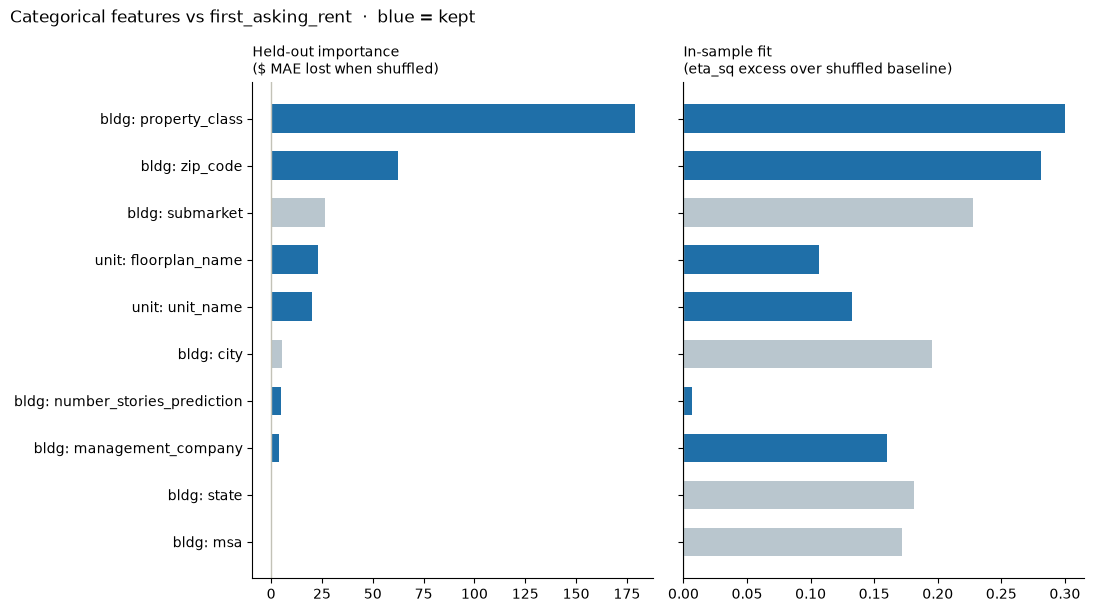

In [6]:
import matplotlib.pyplot as plt

step("Plotting held-out importance beside in-sample fit")
d = final.sort_values("perm_dMAE")
labels = [i.replace("market_building__", "bldg: ").replace("market_unit__", "unit: ") for i in d.index]
colors = ["#1F6FA8" if v == "keep" else "#B9C6CE" for v in d["decision"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 0.42 * len(d) + 2), sharey=True)
for ax, col, title in (
    (axes[0], "perm_dMAE", "Held-out importance\n($ MAE lost when shuffled)"),
    (axes[1], "eta_sq_excess", "In-sample fit\n(eta_sq excess over shuffled baseline)"),
):
    ax.barh(labels, d[col], color=colors, height=0.6)
    ax.set_title(title, loc="left", fontsize=10)
    ax.axvline(0, color="#C3C2B7", lw=1)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

fig.suptitle(f"Categorical features vs {TARGET.split('__')[-1]}  \u00b7  blue = kept", x=0.01, ha="left")
plt.tight_layout()
fig.savefig(out("categorical_importance", "png"), dpi=150)
done(f"wrote {out('categorical_importance', 'png').name}")
plt.show()